## 1. `date_score()` → date_score, remove

In [22]:
import math
import numpy as np
import pandas as pd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import erf
zero_crossing=5
MAX_SCORE = 10
tau = 1 * (60 - zero_crossing) / np.arctanh(0.8)     # ab welchem Abstand (Tage) Punkte als "nah" gelten

def date_score_curve(amp, dist_last):
    return MAX_SCORE * np.tanh(amp / tau * (np.asarray(dist_last, dtype=float) - zero_crossing))



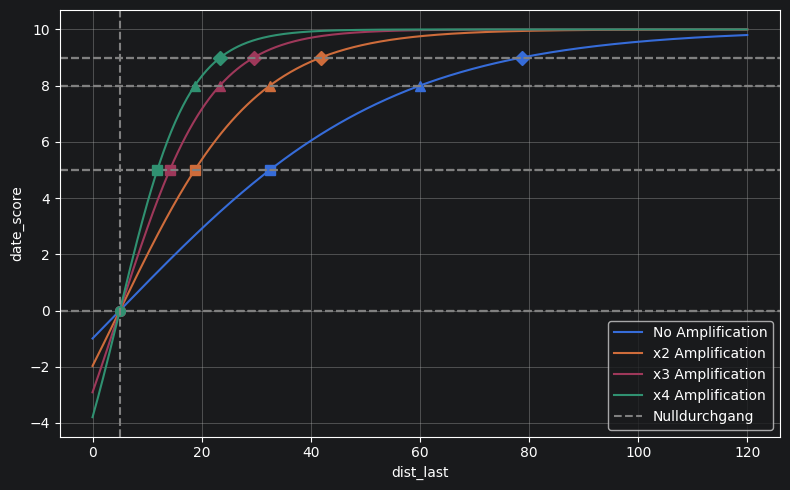

In [23]:
dist_last = np.linspace(0, 120, 500)
amplification={1: "No Amplification", 2: "x2 Amplification", 3: "x3 Amplification", 4: "x4 Amplification"}
LEVELS = {0: "o", 0.5: "s", 0.8: "^", 0.9: "D"}   # Anteil vom Maximum : Marker

fig, ax = plt.subplots(figsize=(8, 5))
for amp,label in amplification.items():
    line, = ax.plot(dist_last, date_score_curve(amp, dist_last), label=label, )
    c = amp / tau
    for p, m in LEVELS.items():
            ax.axhline(p*MAX_SCORE,color="gray",ls="--")
            x = zero_crossing + np.arctanh(p) / c
            if x <= dist_last.max():
                ax.plot(x, p * MAX_SCORE, m, color=line.get_color(), ms=7)
ax.axvline(zero_crossing,color="gray",ls="--",label="Nulldurchgang")
ax.set_xlabel("dist_last")
ax.set_ylabel("date_score")
plt.tight_layout()
ax.legend()
ax.grid()
plt.show()

In [53]:
steepnes=0.3
Max_REWARD = 0.9       # Wdh 0-10: hier keine Verschiebung
mean_durchgang = MAX_SCORE/2+ np.log(1-Max_REWARD)/  steepnes         # Mean bei HAlf SCoRE 5
def repeat_weight(repeat,mean_repeat):
    """Wdh 0-10 -> Anteil der Verschiebung in (-1, 1): 5 -> 0, 10 -> ~-1 (frueher), 0 -> ~+1 (spaeter)."""
    return mean_repeat*np.exp( -(np.asarray(repeat, dtype=float)-mean_durchgang) * steepnes)+mean_repeat*Max_REWARD-mean_repeat



Midpoint Value: 0.0
Midpoint Value: 0.0
Midpoint Value: 0.0


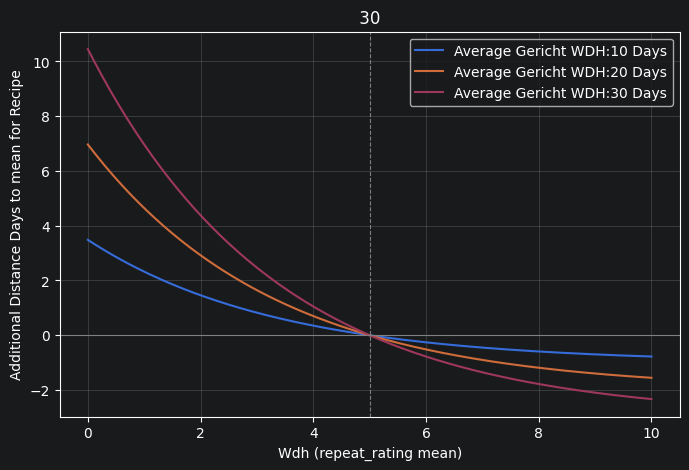

In [54]:
repeats = np.linspace(0, 10, 201)
mean_repeats=[10,20,30] #Wie Oft Gericht im Mean Gekocht Wurde

fig, ax = plt.subplots(figsize=(8, 5))
for mean_repeat in mean_repeats:
    y=repeat_weight(repeats,mean_repeat=mean_repeat)
    ax.plot(repeats, y,label=f"Average Gericht WDH:{mean_repeat} Days")
    print(f"Midpoint Value: {repeat_weight(5,mean_repeat=mean_repeat)}")
ax.axhline(0, color="gray", lw=0.8)
ax.axvline(MAX_SCORE/2, color="gray", lw=0.8, ls="--")
ax.set_xlabel("Wdh (repeat_rating mean)")
ax.set_ylabel("Additional Distance Days to mean for Recipe")
ax.set_title(f" {mean_repeat} ")
ax.legend()
ax.grid(alpha=0.3)

In [55]:
USAGE_WINDOW = 30        # Tage, ueber die die App-Nutzung gezaehlt wird ("ein Monat")
COUNT_USAGE_APP =13 #getUsage(USAGE_WINDOW) Past number of Days App use DURING USAGE_WINDOW
COUNT_RECIPES_COOKED_ATLEAST_TWICE =25 #recipes coooked more equal than twice (Update when you write in that Recipe was counted,Only Up no checking every Recipe everytime)
TARGET_LEVEL = 0.9       # beim Zielabstand T soll die Kurve 90 % vom Max erreichen
#Sigma contains around 68,27 %
def gauss(x, mu=0.0, var=1.0):
    x = np.asarray(x, dtype=float)
    return 1/(np.sqrt(var*2*np.pi)) * np.exp(-0.5 * ((x - mu)**2 )/var)

def fake_gauss(x, mu=0.0, var=1.0,amp=1):
    x = np.asarray(x, dtype=float)
    return amp * np.exp(-0.5 * ((x - mu)**2 )/var)
def ideal_distance_recipe(mean, M, repeat):
    """Zielabstand T = mean + w(repeat) * |M - mean|. Ohne mean (< 2 dates) gilt M."""
    mean = M if np.isnan(mean) else mean
    return mean + repeat_weight(repeat) * abs(M - mean)

def gauss_cdf(x, mu=0.0, var=1.0):
    return 0.5 * (1 + erf((x - mu) / np.sqrt(2 * var)))

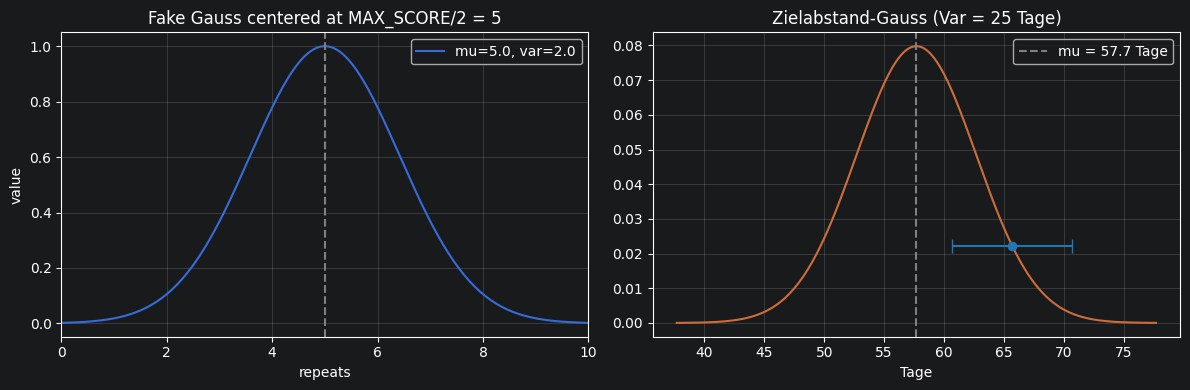

Plot 1: mu = 5.0,  Var = 2.000
Plot 2: mu_days = 57.692, Var = 25
P(60.69230769230768 ≤ X ≤ 70.69230769230768) = 0.2696
push to center  1-P:0.7304080702736447


In [56]:
# Plot 1: Score-Gauss
var_score = 2.0 #points
# Plot 2: Zielabstand-Gauss (in Tagen)
app_mean = USAGE_WINDOW / COUNT_USAGE_APP            # ~2.31 Tage zwischen Nutzungen
mu_days = app_mean * COUNT_RECIPES_COOKED_ATLEAST_TWICE   # ~57.7
var_days = min(30,COUNT_RECIPES_COOKED_ATLEAST_TWICE)                                   # Streuung in Tagen

x0, dx = mu_days+8, 5
a, b = x0 - dx, x0 + dx

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# 1) Gauss um MAX_SCORE/2, x von 0 bis MAX_SCORE
repeats = np.linspace(0, MAX_SCORE, 201)
ax1.plot(repeats, fake_gauss(repeats, mu=MAX_SCORE / 2    , var=var_score),label=f"mu={MAX_SCORE / 2:.1f}, var={var_score}")
ax1.axvline(MAX_SCORE / 2, ls="--", color="gray")
ax1.set_title(f"Fake Gauss centered at MAX_SCORE/2 = {MAX_SCORE / 2:.0f}")
ax1.set_xlabel("repeats")
ax1.set_ylabel("value")
ax1.set_xlim(0, MAX_SCORE)
ax1.legend()
ax1.grid(True, alpha=0.3)

# 2) Gauss um mu (Tage), +/- 4 sigma
x_days = np.linspace(mu_days - 20, mu_days +20, 401)
ax2.plot(x_days,gauss(x_days, mu=mu_days, var=var_days), color="C1")
ax2.axvline(mu_days, ls="--", color="gray", label=f"mu = {mu_days:.1f} Tage")
ax2.errorbar(x0, gauss(x0, mu=mu_days, var=var_days), xerr=dx, fmt='o', capsize=5, color='tab:blue')
ax2.set_title(f"Zielabstand-Gauss (Var = {var_days:.0f} Tage)")
ax2.set_xlabel("Tage")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Plot 1: mu = {MAX_SCORE / 2},  Var = {var_score:.3f}")
print(f"Plot 2: mu_days = {mu_days:.3f}, Var = {var_days}")

p = gauss_cdf(b, mu_days, var_days) - gauss_cdf(a, mu_days, var_days)
print(f"P({a} ≤ X ≤ {b}) = {p:.4f}")
y_max = 1 / np.sqrt(2 * np.pi * var_days)
print(f"push to center  1-P:{1-p}")

In [ ]:
poss_scores = [2, 5, 7, 10]  # repeat-Scores 0-10

for pscore in poss_scores:
    pull = (1 - p) * fake_gauss(pscore, mu=MAX_SCORE / 2, var=var_score)  # 0..1: neutraler Score -> staerker zur Mitte
    to_center = pull * (mu_days - x0)                                     # Tage Richtung mu_days
    shift = repeat_weight(pscore, mean_repeat=x0)                         # Tage durch Score
    ideal = x0 + to_center + shift
    print(f"Score {pscore:>2}: Gericht Wdh {x0:.1f} Tage, Var {var_score} -> "
          f"Mitte {to_center:+.2f}, Score {shift:+.2f} -> neues Goal {ideal:.1f} Tage")


In [ ]:
7

## Sanity Checks

Expected behavior. 🟠 = not tested yet; "old" = value from the old test script, re-check here.

| Situation | Expected | Status |
|---|---|---|
| just cooked | removed / 0 | 🟠 old: 0, removed |
| cooked within 4 days (incl. exactly 4) | removed | 🟠 old: removed |
| 5 days ago | not removed | 🟠 |
| cooked rarely, long ago | high (~2·repeat) | 🟠 old: 9.94 |
| normal rhythm, in between | medium | 🟠 old: 5.18 |
| never cooked | medium | 🟠 old: 5.00 |
| higher repeat ⇒ higher score | monotonically increasing | 🟠 |
| longer ago ⇒ higher score | monotonically increasing | 🟠 |
| always in [0, 10] | – | 🟠 |